# Checkpoint — KMeans & DBSCAN

Dit notebook wordt automatisch gecheckt via pytest (GitHub Actions). De checks voeren je notebook uit en valideren of bepaalde variabelen bestaan en binnen de verwachte ranges vallen. **Je krijgt geen hints in de foutmeldingen: het is aan jou om correct werkende code te schrijven.**

## BELANGRIJK: gebruik exact de genoemde variabelennamen

De checks zoeken volgende variabelen in je notebook. Andere namen worden niet gezien:

- `best_k_wine` — de gekozen waarde van k voor de Wine-dataset (int)
- `silhouette_wine` — de silhouette score van die keuze (float)
- `image` — de ingeladen afbeelding (3D numpy-array)
- `n_colors` — het tuple van aantal kleuren `(10, 8, 6, 4, 2)`
- `segmented_imgs` — de lijst van gesegmenteerde afbeeldingen (5 elementen, zelfde vorm als `image`)
- `best_k_iris` — de gekozen waarde van k voor de Iris-dataset (int)
- `silhouette_iris` — de silhouette score van die keuze (float)
- `best_k_mall` — de gekozen waarde van k voor de Mall-dataset (int)
- `silhouette_mall` — de silhouette score van die keuze (float)
- `antwoord_iris` — meerkeuzevraag 1: `"A"`, `"B"`, `"C"` of `"D"`
- `antwoord_dbscan` — meerkeuzevraag 2: `"A"`, `"B"`, `"C"` of `"D"`

Gebruik overal `random_state=42` (en `n_init=10`) bij KMeans zodat je resultaten reproduceerbaar zijn en binnen de verwachte drempels vallen. Werk met de lokale afbeelding `images/butterfly.jpg` (er wordt niets gedownload).

## Oefening 1 — Wijn

Cluster de Wine-dataset zo optimaal mogelijk met KMeans. De dataset heeft 13 features op verschillende schalen, dus **schaal eerst met `StandardScaler`**.

Probeer verschillende waarden van `k`, bereken telkens de **silhouette score** en kies de `k` met de hoogste score.

Bewaar je keuze in `best_k_wine` en de bijhorende score in `silhouette_wine`.

In [16]:
import numpy as np
from sklearn import datasets
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

wine = datasets.load_wine()
data = wine.data

# Schaal de data zodat alle features gelijk gewicht krijgen
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

Beste k voor Wine: 3 met score 0.2849


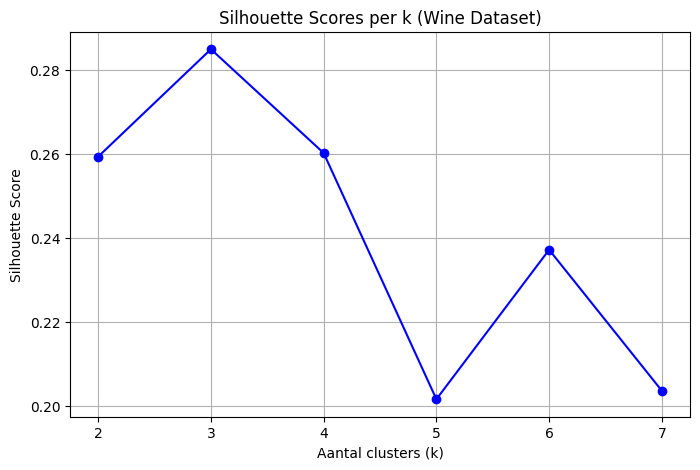

In [18]:
# TODO: bereken voor elke k in range(2, 8) de silhouette score (KMeans met
# random_state=42, n_init=10). Bewaar de k met de hoogste score in best_k_wine
# en die score in silhouette_wine.
best_k_wine = 2
silhouette_wine = 0.0

for k in range(2,8):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, labels)

    if score > silhouette_wine:
        silhouette_wine = score
        best_k_wine = k

print(f"Beste k voor Wine: {best_k_wine} met score {silhouette_wine:.4f}")
# Deze score ligt aan de lage kant. Vanaf 0.65 is het goed.

k_values = range(2, 8)
scores = []

for k in k_values:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(data_scaled)
    scores.append(silhouette_score(data_scaled, labels))

plt.figure(figsize=(8, 5))
plt.plot(k_values, scores, marker='o', linestyle='-', color='b')
plt.title("Silhouette Scores per k (Wine Dataset)")
plt.xlabel("Aantal clusters (k)")
plt.ylabel("Silhouette Score")
plt.grid(True)
plt.show()

## Oefening 2 — Image Segmentation

We gebruiken clustering om een afbeelding in stukken met gelijkaardige kleuren te verdelen. Gebruik de lokale afbeelding `images/butterfly.jpg` (533×800 pixels, 3 kleurkanalen).

Hervorm de 3D-array tot een `(n_pixels, 3)` matrix met `reshape(-1, 3)`, train dan KMeans met `n_clusters` in `(10, 8, 6, 4, 2)` en vervang elke pixel door de centroidkleur van zijn cluster. Hervorm het resultaat terug naar de originele vorm.

Bewaar het tuple `n_colors = (10, 8, 6, 4, 2)` en de 5 gesegmenteerde afbeeldingen in `segmented_imgs`.

In [3]:
import numpy as np
from PIL import Image
from sklearn.cluster import KMeans

# Gebruik het lokale voorbeeldbeeld (geen download nodig)
image = np.asarray(Image.open('images/butterfly.jpg'))
print('image shape:', image.shape)

# Hervorm de 3D-array (pixels, breedte, kanalen) naar een (n_pixels, 3) matrix
X = image.reshape(-1, 3)

image shape: (533, 800, 3)


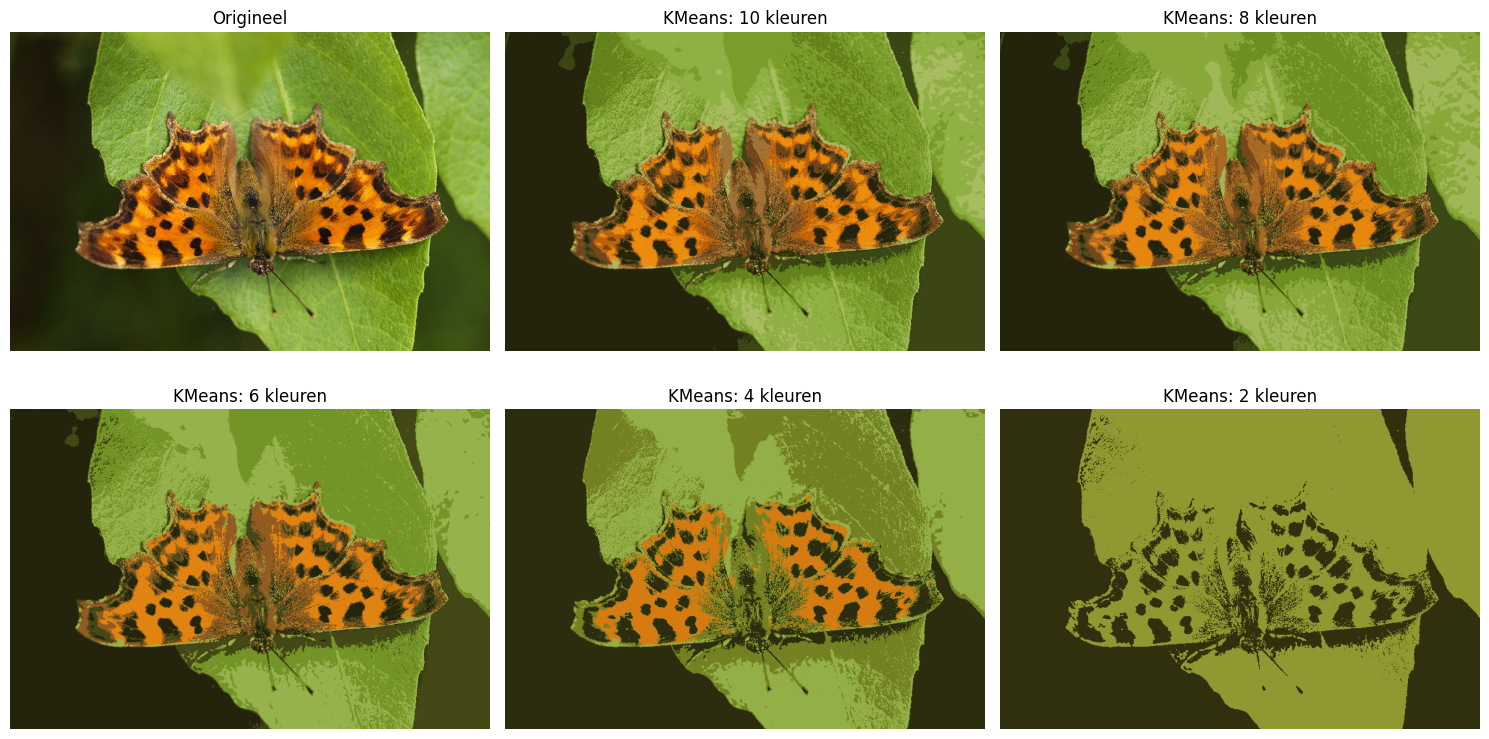

In [19]:
# TODO: train voor elk aantal kleuren een KMeans (random_state=42, n_init=10)
# op X, vervang elke pixel door de centroidkleur van zijn cluster en hervorm
# terug naar image.shape. Bewaar alles in segmented_imgs (volgorde van n_colors).
n_colors = (10, 8, 6, 4, 2)
segmented_imgs = []
for n_clusters in n_colors:
    kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X)
    centroids = kmeans.cluster_centers_
    segmented_img = centroids[labels]
    segmented_imgs.append(segmented_img.reshape(image.shape).astype(np.uint8))

plt.figure(figsize=(15, 8))

# Toon originele afbeelding
plt.subplot(2, 3, 1)
plt.imshow(image)
plt.title("Origineel")
plt.axis('off')

# Toon alle bewerkte afbeeldingen in de loop
for i, (n, img) in enumerate(zip(n_colors, segmented_imgs)):
    plt.subplot(2, 3, i + 2)
    plt.imshow(img)
    plt.title(f"KMeans: {n} kleuren")
    plt.axis('off')

plt.tight_layout()
plt.show()

## Oefening 3 — KMeans vs DBSCAN op Iris

De Iris-dataset bevat 3 soorten die in de feature-ruimte goed gescheiden, **bolvormige** clusters van **gelijkaardige dichtheid** vormen.

Pas zowel KMeans (verschillende `k`) als DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_iris` en de hoogste silhouette in `silhouette_iris`. Beantwoord daarna vraag 1 in `antwoord_iris`.

In [21]:
import numpy as np
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

iris = load_iris()
data_scaled = StandardScaler().fit_transform(iris.data)

# TODO: pas KMeans toe voor k in range(2, 6) en DBSCAN voor een aantal
# (eps, min_samples) combinaties, en vergelijk de silhouette scores.
# Bewaar de gekozen k in best_k_iris en de hoogste silhouette in silhouette_iris.
best_k_iris = 2
silhouette_iris = 0.0

for k in range(2,6):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, labels)

    if score > silhouette_iris:
        silhouette_iris = score
        best_k_iris = k

print(f"KMeans beste score: {silhouette_iris:.4f} (met k={best_k_iris})")

eps_values = np.arange(0.1,1.1,0.1)
min_samples_values = range(1,12,2)

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(data_scaled)

        if len(set(labels)) > 1 and not (len(set(labels)) == 2 and -1 in labels):
            score = silhouette_score(data_scaled, labels)
            print(f"DBSCAN eps={eps}, min_samples={min_samples} -> score: {score:.4f}")



KMeans beste score: 0.5818 (met k=2)
DBSCAN eps=0.1, min_samples=1 -> score: 0.0133
DBSCAN eps=0.2, min_samples=1 -> score: 0.1143
DBSCAN eps=0.2, min_samples=3 -> score: 0.0871
DBSCAN eps=0.30000000000000004, min_samples=1 -> score: 0.1284
DBSCAN eps=0.30000000000000004, min_samples=3 -> score: -0.1473
DBSCAN eps=0.30000000000000004, min_samples=5 -> score: -0.1942
DBSCAN eps=0.30000000000000004, min_samples=7 -> score: 0.1751
DBSCAN eps=0.4, min_samples=1 -> score: 0.0547
DBSCAN eps=0.4, min_samples=3 -> score: 0.1513
DBSCAN eps=0.4, min_samples=5 -> score: 0.0277
DBSCAN eps=0.4, min_samples=7 -> score: -0.1516
DBSCAN eps=0.4, min_samples=9 -> score: 0.2882
DBSCAN eps=0.4, min_samples=11 -> score: 0.2781
DBSCAN eps=0.5, min_samples=1 -> score: 0.0003
DBSCAN eps=0.5, min_samples=3 -> score: 0.1597
DBSCAN eps=0.5, min_samples=5 -> score: 0.3565
DBSCAN eps=0.5, min_samples=7 -> score: 0.1391
DBSCAN eps=0.5, min_samples=9 -> score: 0.0693
DBSCAN eps=0.5, min_samples=11 -> score: 0.0479
D

## Oefening 4 — KMeans vs DBSCAN op Mall

De Mall-dataset (`data/Mall_Customers.csv`) bevat klanten met `Age`, `Annual Income (k$)` en `Spending Score (1-100)`. De clusters hebben **sterk verschillende dichtheden**, waardoor DBSCAN het vaak moeilijk heeft.

Pas KMeans (verschillende `k`) en DBSCAN (verschillende `eps`/`min_samples`) toe op de **gestandaardiseerde** data en vergelijk met de silhouette score. Bewaar je gekozen `k` in `best_k_mall` en de hoogste silhouette in `silhouette_mall`. Beantwoord daarna vraag 2 in `antwoord_dbscan`.

In [13]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

mall = pd.read_csv('data/Mall_Customers.csv')
features = mall[['Age', 'Annual Income (k$)', 'Spending Score (1-100)']]
data_scaled = StandardScaler().fit_transform(features)

# TODO: vergelijk KMeans (verschillende k's) met DBSCAN (verschillende
# eps/min_samples) via de silhouette score. Bewaar de gekozen k in best_k_mall
# en de hoogste silhouette in silhouette_mall.
best_k_mall = 5
silhouette_mall = 0.0

for k in range(2,8):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(data_scaled)
    score = silhouette_score(data_scaled, labels)

    if score > silhouette_mall:
        silhouette_mall = score
        best_k_mall = k

print(f"KMeans beste score: {silhouette_mall:.4f} (met k={best_k_mall})")

eps_values = np.arange(0.1,1.1,0.1)
min_samples_values = range(1,12,2)

for eps in eps_values:
    for min_samples in min_samples_values:
        dbscan = DBSCAN(eps=eps, min_samples=min_samples)
        labels = dbscan.fit_predict(data_scaled)

        if len(set(labels)) > 1 and not (len(set(labels)) == 2 and -1 in labels):
            score = silhouette_score(data_scaled, labels)
            print(f"DBSCAN eps={eps}, min_samples={min_samples} -> score: {score:.4f}")

KMeans beste score: 0.4284 (met k=6)
DBSCAN eps=0.1, min_samples=1 -> score: 0.0220
DBSCAN eps=0.2, min_samples=1 -> score: 0.1299
DBSCAN eps=0.2, min_samples=3 -> score: -0.3283
DBSCAN eps=0.30000000000000004, min_samples=1 -> score: 0.1009
DBSCAN eps=0.30000000000000004, min_samples=3 -> score: -0.0796
DBSCAN eps=0.30000000000000004, min_samples=5 -> score: -0.1822
DBSCAN eps=0.4, min_samples=1 -> score: 0.1176
DBSCAN eps=0.4, min_samples=3 -> score: 0.1513
DBSCAN eps=0.4, min_samples=5 -> score: 0.0760
DBSCAN eps=0.4, min_samples=7 -> score: -0.0461
DBSCAN eps=0.4, min_samples=9 -> score: -0.1507
DBSCAN eps=0.5, min_samples=1 -> score: -0.0710
DBSCAN eps=0.5, min_samples=3 -> score: 0.1316
DBSCAN eps=0.5, min_samples=5 -> score: 0.1845
DBSCAN eps=0.5, min_samples=7 -> score: 0.2236
DBSCAN eps=0.5, min_samples=9 -> score: 0.1092
DBSCAN eps=0.5, min_samples=11 -> score: -0.0227
DBSCAN eps=0.6, min_samples=1 -> score: -0.1860
DBSCAN eps=0.6, min_samples=3 -> score: 0.1779
DBSCAN eps=0.

## Meerkeuzevragen

### Vraag 1 — Iris
Op de Iris-dataset haalt KMeans een veel hogere silhouette score dan DBSCAN. Wat is de belangrijkste reden?

- **A)** De clusters zijn bolvormig en hebben een gelijkaardige dichtheid, waarvoor KMeans goed geschikt is; DBSCAN kampt met de dichtheidsverschillen.
- **B)** KMeans werkt zonder features te standaardiseren.
- **C)** DBSCAN kan nooit meer dan 2 clusters vinden.
- **D)** KMeans kent het aantal clusters op voorhand, en dat is altijd beter.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_iris`.

### Vraag 2 — DBSCAN
Wanneer is DBSCAN een betere keuze dan KMeans?

- **A)** Wanneer de clusters een onregelmatige, niet-bolvormige vorm hebben of er outliers/ruis zijn.
- **B)** Wanneer alle clusters bolvormig en even groot zijn.
- **C)** Wanneer je altijd precies `k` clusters nodig hebt.
- **D)** Wanneer de dataset klein is en je snel wilt clusteren.

Bewaar je antwoord (`"A"`, `"B"`, `"C"` of `"D"`) in `antwoord_dbscan`.

In [15]:
# Vraag 1: antwoord_iris = "A", "B", "C" of "D"
antwoord_iris = "A"

# Vraag 2: antwoord_dbscan = "A", "B", "C" of "D"
antwoord_dbscan = "A"
